In [1]:
# ============================================================
# CONVNEXT-TINY — COMPLETE CELL 1
# Setup + Fixed Split + DataLoader + Model + Functions
# Shared-Drive Shortcut Compatible
# ============================================================


# ============================================================
# 0. INSTALL PACKAGES
# ============================================================

!pip -q install -U timm fvcore scipy statsmodels openpyxl


# ============================================================
# MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=False
)


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import gc
import time
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms

from torchvision.transforms import (
    InterpolationMode
)

import timm

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

warnings.filterwarnings(
    "ignore"
)


# ============================================================
# 2. EXPERIMENTAL CONFIGURATION
# Same settings used for all models
# ============================================================

SEED = 42

IMG_SIZE = 224

BATCH_SIZE = 32

EPOCHS = 30

LEARNING_RATE = 1e-4

N_FOLDS = 5

THRESHOLD = 0.50

NUM_WORKERS = 0


# ============================================================
# 3. MODEL INFORMATION
# ============================================================

MODEL_NAME = "ConvNeXt-Tiny"

TIMM_MODEL_NAME = (
    "convnext_tiny.fb_in22k_ft_in1k"
)


# ============================================================
# 4. CLASS INFORMATION
# ============================================================

CLASS_NAMES = [
    "encroachment_present",
    "no_encroachment"
]


CLASS_TO_IDX = {
    "encroachment_present": 0,
    "no_encroachment": 1
}


IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)


# ============================================================
# 5. LOCATE ACTUAL Brishty_ml SHORTCUT TARGET
# ============================================================

print(
    "=" * 75
)

print(
    "LOCATING Brishty_ml SHARED-DRIVE SHORTCUT"
)

print(
    "=" * 75
)


BRISHTY_ROOT = None


# ------------------------------------------------------------
# First try normal MyDrive path
# ------------------------------------------------------------

normal_brishty_root = Path(
    "/content/drive/MyDrive/Brishty_ml"
)


normal_dataset_dir = (
    normal_brishty_root /
    "sevd_final" /
    "images"
)


if (
    normal_dataset_dir /
    "encroachment_present"
).is_dir() and (
    normal_dataset_dir /
    "no_encroachment"
).is_dir():

    BRISHTY_ROOT = (
        normal_brishty_root
    )


# ------------------------------------------------------------
# If shortcut is not directly visible,
# search actual shortcut targets
# ------------------------------------------------------------

if BRISHTY_ROOT is None:

    shortcut_root = Path(
        "/content/drive/.shortcut-targets-by-id"
    )


    if shortcut_root.exists():

        print(
            "Searching shortcut targets..."
        )


        for sevd_folder in shortcut_root.rglob(
            "sevd_final"
        ):

            if not sevd_folder.is_dir():

                continue


            candidate_dataset_dir = (
                sevd_folder /
                "images"
            )


            candidate_class_1 = (
                candidate_dataset_dir /
                "encroachment_present"
            )


            candidate_class_2 = (
                candidate_dataset_dir /
                "no_encroachment"
            )


            if (
                candidate_class_1.is_dir()
                and
                candidate_class_2.is_dir()
            ):

                BRISHTY_ROOT = (
                    sevd_folder.parent
                )

                break


# ------------------------------------------------------------
# Final fallback search
# ------------------------------------------------------------

if BRISHTY_ROOT is None:

    drive_root = Path(
        "/content/drive"
    )


    print(
        "Running fallback search..."
    )


    for images_folder in drive_root.rglob(
        "images"
    ):

        if not images_folder.is_dir():

            continue


        if images_folder.parent.name != (
            "sevd_final"
        ):

            continue


        class_1 = (
            images_folder /
            "encroachment_present"
        )


        class_2 = (
            images_folder /
            "no_encroachment"
        )


        if (
            class_1.is_dir()
            and
            class_2.is_dir()
        ):

            BRISHTY_ROOT = (
                images_folder
                .parent
                .parent
            )

            break


# ============================================================
# 6. FINAL PATH CHECK
# ============================================================

if BRISHTY_ROOT is None:

    raise FileNotFoundError(
        "Could not locate the Brishty_ml shortcut target.\n"
        "Expected structure:\n"
        "Brishty_ml/sevd_final/images/"
        "encroachment_present\n"
        "Brishty_ml/sevd_final/images/"
        "no_encroachment"
    )


DATASET_DIR = (
    BRISHTY_ROOT /
    "sevd_final" /
    "images"
)


OUTPUT_DIR = (
    BRISHTY_ROOT /
    "reviewer_final_results"
)


print(
    "\nActual Brishty_ml location:"
)

print(
    BRISHTY_ROOT
)


print(
    "\nActual dataset path:"
)

print(
    DATASET_DIR
)


print(
    "\nActual output path:"
)

print(
    OUTPUT_DIR
)


# ============================================================
# 7. OUTPUT PATHS
# ============================================================

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


COMPLETE_SPLIT_PATH = (
    OUTPUT_DIR /
    "fixed_test_and_5fold_split.csv"
)


FOLD_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_5fold_development_set.csv"
)


TEST_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)


MODEL_OUTPUT_DIR = (
    OUTPUT_DIR /
    "03_ConvNeXt_Tiny"
)


MODEL_DIR = (
    MODEL_OUTPUT_DIR /
    "saved_models"
)


HISTORY_DIR = (
    MODEL_OUTPUT_DIR /
    "training_history"
)


FIGURE_DIR = (
    MODEL_OUTPUT_DIR /
    "figures"
)


PREDICTION_DIR = (
    MODEL_OUTPUT_DIR /
    "predictions"
)


METRIC_DIR = (
    MODEL_OUTPUT_DIR /
    "metrics"
)


for folder in [

    MODEL_OUTPUT_DIR,
    MODEL_DIR,
    HISTORY_DIR,
    FIGURE_DIR,
    PREDICTION_DIR,
    METRIC_DIR

]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 8. DEVICE AND REPRODUCIBILITY
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


def set_seed(
    seed=42
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(
        seed
    )

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    torch.cuda.manual_seed_all(
        seed
    )

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed(
    SEED
)


# ============================================================
# 9. DATASET SAFETY CHECK
# ============================================================

if not DATASET_DIR.exists():

    raise FileNotFoundError(
        f"Dataset folder not found:\n"
        f"{DATASET_DIR}"
    )


for class_name in CLASS_NAMES:

    class_folder = (
        DATASET_DIR /
        class_name
    )


    if not class_folder.exists():

        raise FileNotFoundError(
            f"Class folder not found:\n"
            f"{class_folder}"
        )


print(
    "\nDataset folders verified."
)


# ============================================================
# 10. COLLECT IMAGES
# ============================================================

def collect_images(
    dataset_dir
):

    image_paths = []
    labels = []


    for class_name in CLASS_NAMES:

        class_folder = (
            dataset_dir /
            class_name
        )


        for root, directories, files in os.walk(
            class_folder
        ):

            directories.sort()


            for file_name in sorted(
                files
            ):

                if file_name.lower().endswith(
                    IMAGE_EXTENSIONS
                ):

                    image_paths.append(

                        str(
                            Path(root) /
                            file_name
                        )
                    )


                    labels.append(

                        CLASS_TO_IDX[
                            class_name
                        ]
                    )


    return (

        np.asarray(
            image_paths
        ),

        np.asarray(
            labels,
            dtype=np.int64
        )
    )


# ============================================================
# 11. LOAD OR CREATE FIXED SPLITS
# ============================================================

if (
    FOLD_CSV_PATH.exists()
    and
    TEST_CSV_PATH.exists()
):

    print(
        "\nExisting fixed split files found."
    )


    development_df = pd.read_csv(
        FOLD_CSV_PATH
    )


    test_df = pd.read_csv(
        TEST_CSV_PATH
    )


else:

    print(
        "\nFixed split files not found. "
        "Creating them with the same settings."
    )


    all_image_paths, all_labels = (
        collect_images(
            DATASET_DIR
        )
    )


    if len(
        all_image_paths
    ) == 0:

        raise RuntimeError(
            "No images were found."
        )


    print(
        "Total images:",
        len(
            all_image_paths
        )
    )


    for class_name, class_index in (
        CLASS_TO_IDX.items()
    ):

        print(
            class_name,
            int(
                np.sum(
                    all_labels ==
                    class_index
                )
            )
        )


    (
        development_paths,
        test_paths,
        development_labels,
        test_labels
    ) = train_test_split(

        all_image_paths,
        all_labels,

        test_size=0.15,

        random_state=SEED,

        stratify=all_labels,

        shuffle=True
    )


    development_fold_ids = np.zeros(

        len(
            development_paths
        ),

        dtype=np.int64
    )


    stratified_kfold = StratifiedKFold(

        n_splits=N_FOLDS,

        shuffle=True,

        random_state=SEED
    )


    for fold_number, (
        _,
        validation_indices
    ) in enumerate(

        stratified_kfold.split(

            development_paths,

            development_labels
        ),

        start=1
    ):

        development_fold_ids[
            validation_indices
        ] = fold_number


    development_df = pd.DataFrame({

        "image_path":
            development_paths,

        "label":
            development_labels.astype(
                int
            ),

        "class_name": [

            CLASS_NAMES[
                int(label)
            ]

            for label in
            development_labels
        ],

        "dataset_role":
            "development",

        "fold_id":
            development_fold_ids
    })


    test_df = pd.DataFrame({

        "image_path":
            test_paths,

        "label":
            test_labels.astype(
                int
            ),

        "class_name": [

            CLASS_NAMES[
                int(label)
            ]

            for label in
            test_labels
        ],

        "dataset_role":
            "test",

        "fold_id":
            0
    })


    complete_split_df = pd.concat(

        [
            development_df,
            test_df
        ],

        ignore_index=True
    )


    development_df.to_csv(
        FOLD_CSV_PATH,
        index=False
    )


    test_df.to_csv(
        TEST_CSV_PATH,
        index=False
    )


    complete_split_df.to_csv(
        COMPLETE_SPLIT_PATH,
        index=False
    )


# ============================================================
# 12. STANDARDIZE DATA TYPES
# ============================================================

development_df[
    "label"
] = (
    development_df[
        "label"
    ]
    .astype(int)
)


development_df[
    "fold_id"
] = (
    development_df[
        "fold_id"
    ]
    .astype(int)
)


test_df[
    "label"
] = (
    test_df[
        "label"
    ]
    .astype(int)
)


available_folds = sorted(

    development_df[
        "fold_id"
    ]
    .unique()
    .tolist()
)


if available_folds != [
    1,
    2,
    3,
    4,
    5
]:

    raise ValueError(
        f"Unexpected fold IDs: "
        f"{available_folds}"
    )


# ============================================================
# 13. VERIFY IMAGE PATHS
# ============================================================

missing_development = (

    ~development_df[
        "image_path"
    ].apply(
        lambda path:
            Path(path).exists()
    )

).sum()


missing_test = (

    ~test_df[
        "image_path"
    ].apply(
        lambda path:
            Path(path).exists()
    )

).sum()


print(
    "\nMissing development images:",
    int(
        missing_development
    )
)


print(
    "Missing test images:",
    int(
        missing_test
    )
)


if missing_development > 0:

    raise FileNotFoundError(
        f"{missing_development} development "
        f"images are missing."
    )


if missing_test > 0:

    raise FileNotFoundError(
        f"{missing_test} test images are missing."
    )


# ============================================================
# 14. PREPROCESSING
# Same augmentation policy as original ConvNeXt code
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]


IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


train_transform = transforms.Compose([

    transforms.Resize(

        (
            IMG_SIZE,
            IMG_SIZE
        ),

        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),


    transforms.RandomHorizontalFlip(
        p=0.50
    ),


    transforms.RandomRotation(

        degrees=36,

        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),


    transforms.RandomAffine(

        degrees=0,

        scale=(
            0.90,
            1.10
        ),

        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),


    transforms.ToTensor(),


    transforms.Normalize(

        mean=IMAGENET_MEAN,

        std=IMAGENET_STD
    )
])


evaluation_transform = transforms.Compose([

    transforms.Resize(

        (
            IMG_SIZE,
            IMG_SIZE
        ),

        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),


    transforms.ToTensor(),


    transforms.Normalize(

        mean=IMAGENET_MEAN,

        std=IMAGENET_STD
    )
])


# ============================================================
# 15. DATASET CLASS
# ============================================================

class SEVDDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.transform = (
            transform
        )


    def __len__(
        self
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = (
            self.dataframe
            .iloc[
                index
            ]
        )


        image_path = str(
            row[
                "image_path"
            ]
        )


        label = float(
            row[
                "label"
            ]
        )


        try:

            with Image.open(
                image_path
            ) as opened_image:

                image = (
                    opened_image
                    .convert(
                        "RGB"
                    )
                )


        except Exception as error:

            raise RuntimeError(
                f"Unable to load image:\n"
                f"{image_path}"
            ) from error


        if self.transform is not None:

            image = self.transform(
                image
            )


        return {

            "image":
                image,

            "label":
                torch.tensor(
                    label,
                    dtype=torch.float32
                ),

            "image_path":
                image_path
        }


# ============================================================
# 16. DATALOADER FUNCTION
# ============================================================

def create_dataloader(
    dataframe,
    transform,
    shuffle,
    fold_seed=SEED
):

    dataset = SEVDDataset(

        dataframe=dataframe,

        transform=transform
    )


    generator = torch.Generator()


    generator.manual_seed(
        fold_seed
    )


    dataloader = DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=shuffle,

        num_workers=NUM_WORKERS,

        pin_memory=(
            torch.cuda.is_available()
        ),

        persistent_workers=False,

        drop_last=False,

        generator=(
            generator
            if shuffle
            else None
        )
    )


    return (
        dataset,
        dataloader
    )


# ============================================================
# 17. FIXED TEST DATALOADER
# ============================================================

test_dataset, test_loader = (
    create_dataloader(

        dataframe=test_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=SEED
    )
)


# ============================================================
# 18. MODEL DEFINITION
# ============================================================

class ConvNeXtTinyBinaryClassifier(
    nn.Module
):

    def __init__(
        self,
        dropout_rate=0.4
    ):

        super().__init__()


        self.backbone = timm.create_model(

            TIMM_MODEL_NAME,

            pretrained=True,

            num_classes=0,

            global_pool="avg"
        )


        for parameter in (
            self.backbone.parameters()
        ):

            parameter.requires_grad = False


        self.feature_dimension = (
            self.backbone.num_features
        )


        self.dropout = nn.Dropout(
            p=dropout_rate
        )


        self.binary_output = nn.Linear(

            self.feature_dimension,

            1
        )


    def forward(
        self,
        images
    ):

        features = self.backbone(
            images
        )


        features = self.dropout(
            features
        )


        logits = self.binary_output(
            features
        )


        return logits.squeeze(
            dim=1
        )


# ============================================================
# 19. MODEL BUILDER
# ============================================================

def build_convnext_tiny_model():

    model = ConvNeXtTinyBinaryClassifier(
        dropout_rate=0.4
    ).to(
        DEVICE
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.Adam(

        filter(
            lambda parameter:
                parameter.requires_grad,

            model.parameters()
        ),

        lr=LEARNING_RATE
    )


    return (
        model,
        criterion,
        optimizer
    )


# ============================================================
# 20. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    epoch_number
):

    model.train()

    model.backbone.eval()


    total_loss = 0.0

    all_labels = []

    all_predictions = []


    progress_bar = tqdm(

        dataloader,

        desc=(
            f"Epoch {epoch_number:02d}/{EPOCHS} "
            f"Training"
        ),

        leave=False
    )


    for batch in progress_bar:

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )


        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        logits = model(
            images
        )


        loss = criterion(
            logits,
            labels
        )


        loss.backward()

        optimizer.step()


        probabilities = torch.sigmoid(
            logits
        )


        predictions = (
            probabilities >=
            THRESHOLD
        ).long()


        batch_size = images.size(
            0
        )


        total_loss += (
            loss.item() *
            batch_size
        )


        all_labels.extend(

            labels
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        all_predictions.extend(

            predictions
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        progress_bar.set_postfix(
            loss=(
                f"{loss.item():.4f}"
            )
        )


    return {

        "loss":
            float(
                total_loss /
                len(
                    dataloader.dataset
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    all_labels,
                    all_predictions
                )
            )
    }


# ============================================================
# 21. EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    dataloader,
    criterion,
    description="Validation"
):

    model.eval()


    total_loss = 0.0

    all_labels = []

    all_probabilities = []

    all_predictions = []

    all_image_paths = []


    progress_bar = tqdm(

        dataloader,

        desc=description,

        leave=False
    )


    with torch.no_grad():

        for batch in progress_bar:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )


            labels = batch[
                "label"
            ].to(
                DEVICE,
                non_blocking=True
            )


            logits = model(
                images
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = torch.sigmoid(
                logits
            )


            predictions = (
                probabilities >=
                THRESHOLD
            ).long()


            batch_size = images.size(
                0
            )


            total_loss += (
                loss.item() *
                batch_size
            )


            all_labels.extend(

                labels
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_probabilities.extend(

                probabilities
                .cpu()
                .numpy()
                .tolist()
            )


            all_predictions.extend(

                predictions
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_image_paths.extend(
                batch[
                    "image_path"
                ]
            )


    labels_array = np.asarray(
        all_labels,
        dtype=int
    )


    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float
    )


    predictions_array = np.asarray(
        all_predictions,
        dtype=int
    )


    confusion = confusion_matrix(

        labels_array,

        predictions_array,

        labels=[
            0,
            1
        ]
    )


    return {

        "loss":
            float(
                total_loss /
                len(
                    dataloader.dataset
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    labels_array,
                    predictions_array
                )
            ),

        "precision":
            float(
                precision_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "f1_score":
            float(
                f1_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "auc":
            float(
                roc_auc_score(
                    labels_array,
                    probabilities_array
                )
            ),

        "true_negative":
            int(
                confusion[
                    0,
                    0
                ]
            ),

        "false_positive":
            int(
                confusion[
                    0,
                    1
                ]
            ),

        "false_negative":
            int(
                confusion[
                    1,
                    0
                ]
            ),

        "true_positive":
            int(
                confusion[
                    1,
                    1
                ]
            ),

        "true_labels":
            labels_array,

        "probabilities":
            probabilities_array,

        "predictions":
            predictions_array,

        "image_paths":
            np.asarray(
                all_image_paths,
                dtype=str
            )
    }


# ============================================================
# 22. SAFETY CHECK
# ============================================================

check_train_df = development_df[

    development_df[
        "fold_id"
    ] != 1

].reset_index(
    drop=True
)


check_dataset, check_loader = (
    create_dataloader(

        dataframe=check_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            1
        )
    )
)


sample_batch = next(
    iter(
        check_loader
    )
)


verification_model, _, _ = (
    build_convnext_tiny_model()
)


verification_model.eval()


with torch.no_grad():

    dummy_output = verification_model(

        sample_batch[
            "image"
        ][:2].to(
            DEVICE
        )
    )


backbone_trainable_parameters = sum(

    parameter.numel()

    for parameter in
    verification_model.backbone.parameters()

    if parameter.requires_grad
)


assert sample_batch[
    "image"
].shape[
    1:
] == (
    3,
    IMG_SIZE,
    IMG_SIZE
)


assert dummy_output.shape == (
    2,
)


assert backbone_trainable_parameters == 0


# ============================================================
# 23. FINAL OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 75
)

print(
    "CONVNEXT-TINY CELL 1 COMPLETED"
)

print(
    "=" * 75
)


print(
    "Device:",
    DEVICE
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(
            0
        )
    )


print(
    "\nActual Brishty_ml:"
)

print(
    BRISHTY_ROOT
)


print(
    "\nDataset:"
)

print(
    DATASET_DIR
)


print(
    "\nOutput:"
)

print(
    OUTPUT_DIR
)


print(
    "\nDevelopment images:",
    len(
        development_df
    )
)


print(
    "Test images:",
    len(
        test_df
    )
)


print(
    "Fold IDs:",
    available_folds
)


print(
    "Batch shape:",
    sample_batch[
        "image"
    ].shape
)


print(
    "Dummy output shape:",
    dummy_output.shape
)


print(
    "Backbone frozen:",
    backbone_trainable_parameters == 0
)


print(
    "Model output folder:",
    MODEL_OUTPUT_DIR
)


del verification_model

del check_loader

del check_dataset


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.9/65.9 kB 3.8 MB/s eta 0:00:00
Mounted at /content/drive
LOCATING Brishty_ml SHARED-DRIVE SHORTCUT

Actual Brishty_ml location:
/content/drive/MyDrive/Brishty_ml

Actual dataset path:
/content/drive/MyDrive/Brishty_ml/sevd_final/images

Actual output path:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results

Dataset folders verified.

Existing fixed split files found.

Missing development images: 0
Missing test images: 0


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            


CONVNEXT-TINY CELL 1 COMPLETED
Device: cuda
GPU: Tesla T4

Actual Brishty_ml:
/content/drive/MyDrive/Brishty_ml

Dataset:
/content/drive/MyDrive/Brishty_ml/sevd_final/images

Output:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results

Development images: 6299
Test images: 1112
Fold IDs: [1, 2, 3, 4, 5]
Batch shape: torch.Size([32, 3, 224, 224])
Dummy output shape: torch.Size([2])
Backbone frozen: True
Model output folder: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny



STARTING ConvNeXt-Tiny FOLD 4/5
Training images: 5039
Validation images: 1260
Independent test images: 1112


Epoch 01/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 01/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 4 | Epoch 01/30 - loss: 0.4695 - accuracy: 0.7938 - val_loss: 0.2630 - val_accuracy: 0.9619


Epoch 02/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 4 | Epoch 30/30 - loss: 0.0357 - accuracy: 0.9917 - val_loss: 0.0164 - val_accuracy: 0.9984


Fold 4 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 4 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

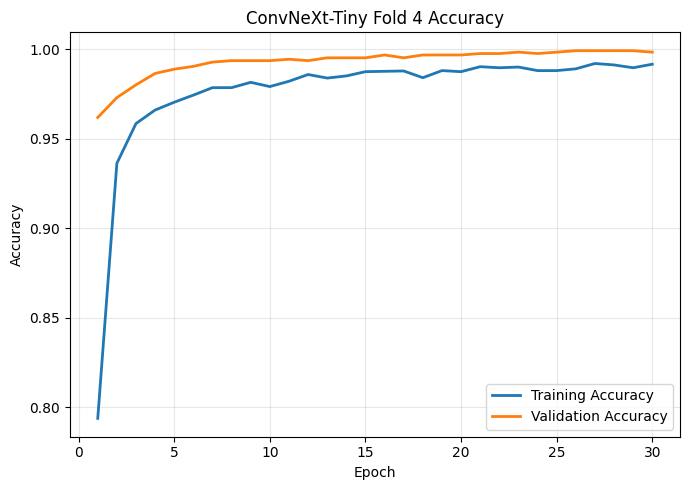

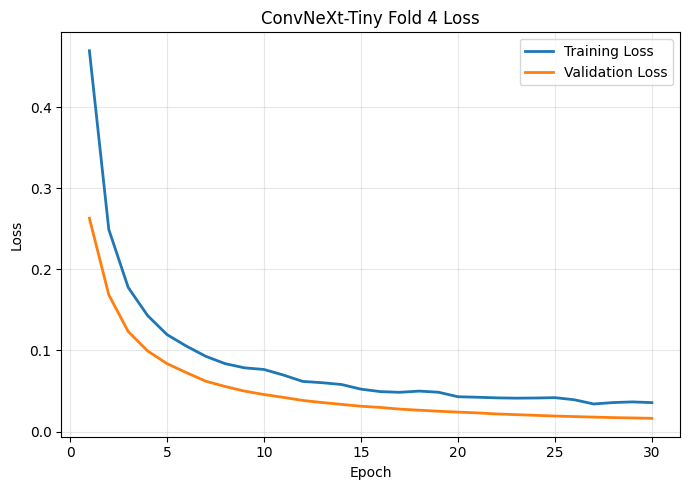


Fold 4 training time: 165.59 minutes

Validation result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,ConvNeXt-Tiny,4,validation,0.016351,0.998413,0.998328,0.998328,0.998328,0.999987,661,1,1,597,9935.188298,165.586472



Independent test result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,ConvNeXt-Tiny,4,test,0.023989,0.993705,0.994307,0.992424,0.993365,0.999812,581,3,4,524,9935.188298,165.586472



Saved model: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/saved_models/ConvNeXt-Tiny_fold_4.pth
Saved history: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/training_history/ConvNeXt-Tiny_fold_4_history.csv
Saved accuracy graph: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/figures/ConvNeXt-Tiny_fold_4_accuracy.png
Saved loss graph: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/figures/ConvNeXt-Tiny_fold_4_loss.png
Saved validation predictions: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/predictions/ConvNeXt-Tiny_fold_4_validation_predictions.csv
Saved test predictions: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/predictions/ConvNeXt-Tiny_fold_4_test_predictions.csv
Saved summary: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/metrics/ConvNeXt-Tiny_fold_4_summary.csv

ConvNeXt-Tiny FOLD 4

...

Fold 5 | Epoch 01/30 - loss: 0.5150 - accuracy: 0.7496 - val_loss: 0.3184 - val_accuracy: 0.9230


Epoch 02/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 02/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 5 | Epoch 02/30 - loss: 0.2687 - accuracy: 0.9282 - val_loss: 0.1997 - val_accuracy: 0.9539


Epoch 03/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# CONVNEXT-TINY — COMPLETE CELL 2
# TRAIN ONLY FOLD 4 AND FOLD 5
# Same original training/evaluation/saving logic
# ============================================================


# ============================================================
# 1. SAVE HISTORY AND GRAPHS
# ============================================================

def save_history_and_graphs(
    history_dictionary,
    fold_number
):

    history_df = pd.DataFrame(
        history_dictionary
    )

    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )


    history_path = (
        HISTORY_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )


    # ========================================================
    # ACCURACY GRAPH
    # ========================================================

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["accuracy"],
        linewidth=2,
        label="Training Accuracy"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"],
        linewidth=2,
        label="Validation Accuracy"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Accuracy"
    )

    plt.title(
        f"ConvNeXt-Tiny Fold {fold_number} Accuracy"
    )

    plt.legend()

    plt.grid(
        alpha=0.30
    )

    plt.tight_layout()


    accuracy_path = (
        FIGURE_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_accuracy.png"
    )

    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    # ========================================================
    # LOSS GRAPH
    # ========================================================

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["loss"],
        linewidth=2,
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        linewidth=2,
        label="Validation Loss"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Loss"
    )

    plt.title(
        f"ConvNeXt-Tiny Fold {fold_number} Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.30
    )

    plt.tight_layout()


    loss_path = (
        FIGURE_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_loss.png"
    )

    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    return (
        history_df,
        history_path,
        accuracy_path,
        loss_path
    )


# ============================================================
# 2. SAVE PREDICTIONS
# ============================================================

def save_predictions(
    evaluation_result,
    fold_number,
    dataset_name
):

    prediction_df = pd.DataFrame({

        "image_path":
            evaluation_result[
                "image_paths"
            ],

        "label":
            evaluation_result[
                "true_labels"
            ],

        "class_name": [
            CLASS_NAMES[
                int(label)
            ]

            for label in
            evaluation_result[
                "true_labels"
            ]
        ],

        "predicted_probability_class_1":
            evaluation_result[
                "probabilities"
            ],

        "predicted_label":
            evaluation_result[
                "predictions"
            ],

        "predicted_class_name": [
            CLASS_NAMES[
                int(label)
            ]

            for label in
            evaluation_result[
                "predictions"
            ]
        ]
    })


    prediction_df[
        "correct_prediction"
    ] = (
        prediction_df[
            "label"
        ]
        ==
        prediction_df[
            "predicted_label"
        ]
    )


    prediction_path = (
        PREDICTION_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_"
        f"{dataset_name}_predictions.csv"
    )


    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    return prediction_path


# ============================================================
# 3. SAVE MODEL
# ============================================================

def save_checkpoint(
    model,
    fold_number
):

    checkpoint_path = (
        MODEL_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}.pth"
    )


    torch.save(

        {

            "model_name":
                MODEL_NAME,

            "timm_model_name":
                TIMM_MODEL_NAME,

            "fold":
                fold_number,

            "image_size":
                IMG_SIZE,

            "batch_size":
                BATCH_SIZE,

            "epochs":
                EPOCHS,

            "learning_rate":
                LEARNING_RATE,

            "threshold":
                THRESHOLD,

            "class_names":
                CLASS_NAMES,

            "class_to_idx":
                CLASS_TO_IDX,

            "model_state_dict":
                model.state_dict()
        },

        checkpoint_path
    )


    return checkpoint_path


# ============================================================
# 4. CREATE SUMMARY ROW
# ============================================================

def create_summary_row(
    result,
    fold_number,
    dataset_name,
    training_time_seconds
):

    return {

        "model":
            MODEL_NAME,

        "fold":
            fold_number,

        "dataset":
            dataset_name,

        "loss":
            result[
                "loss"
            ],

        "accuracy":
            result[
                "accuracy"
            ],

        "precision":
            result[
                "precision"
            ],

        "recall":
            result[
                "recall"
            ],

        "f1_score":
            result[
                "f1_score"
            ],

        "auc":
            result[
                "auc"
            ],

        "true_negative":
            result[
                "true_negative"
            ],

        "false_positive":
            result[
                "false_positive"
            ],

        "false_negative":
            result[
                "false_negative"
            ],

        "true_positive":
            result[
                "true_positive"
            ],

        "training_time_seconds":
            training_time_seconds,

        "training_time_minutes":
            training_time_seconds /
            60
    }


# ============================================================
# 5. TRAIN ONLY FOLD 4 AND FOLD 5
# ============================================================

all_summary_rows = []


for fold_number in range(
    4,
    6
):

    print(
        "\n" +
        "=" * 80
    )


    print(
        f"STARTING ConvNeXt-Tiny "
        f"FOLD {fold_number}/{N_FOLDS}"
    )


    print(
        "=" * 80
    )


    # ========================================================
    # FOLD TRAINING DATA
    # ========================================================

    fold_train_df = development_df[

        development_df[
            "fold_id"
        ] != fold_number

    ].reset_index(
        drop=True
    )


    # ========================================================
    # FOLD VALIDATION DATA
    # ========================================================

    fold_validation_df = development_df[

        development_df[
            "fold_id"
        ] == fold_number

    ].reset_index(
        drop=True
    )


    print(
        "Training images:",
        len(
            fold_train_df
        )
    )


    print(
        "Validation images:",
        len(
            fold_validation_df
        )
    )


    print(
        "Independent test images:",
        len(
            test_df
        )
    )


    # ========================================================
    # TRAIN DATALOADER
    # ========================================================

    (
        fold_train_dataset,
        fold_train_loader
    ) = create_dataloader(

        dataframe=fold_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    # ========================================================
    # VALIDATION DATALOADER
    # ========================================================

    (
        fold_validation_dataset,
        fold_validation_loader
    ) = create_dataloader(

        dataframe=fold_validation_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    # ========================================================
    # SAME FOLD-SPECIFIC SEED
    # ========================================================

    set_seed(
        SEED +
        fold_number
    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    # ========================================================
    # BUILD FRESH CONVNEXT-TINY
    # ========================================================

    model, criterion, optimizer = (
        build_convnext_tiny_model()
    )


    history_dictionary = {

        "loss":
            [],

        "accuracy":
            [],

        "val_loss":
            [],

        "val_accuracy":
            []
    }


    # ========================================================
    # START TRAINING TIMER
    # ========================================================

    training_start_time = (
        time.perf_counter()
    )


    # ========================================================
    # ACTUAL 30-EPOCH TRAINING
    # ========================================================

    for epoch_number in range(
        1,
        EPOCHS + 1
    ):

        training_result = (
            train_one_epoch(

                model=model,

                dataloader=(
                    fold_train_loader
                ),

                criterion=criterion,

                optimizer=optimizer,

                epoch_number=(
                    epoch_number
                )
            )
        )


        validation_result = (
            evaluate_model(

                model=model,

                dataloader=(
                    fold_validation_loader
                ),

                criterion=criterion,

                description=(
                    f"Epoch "
                    f"{epoch_number:02d}/"
                    f"{EPOCHS} Validation"
                )
            )
        )


        history_dictionary[
            "loss"
        ].append(
            training_result[
                "loss"
            ]
        )


        history_dictionary[
            "accuracy"
        ].append(
            training_result[
                "accuracy"
            ]
        )


        history_dictionary[
            "val_loss"
        ].append(
            validation_result[
                "loss"
            ]
        )


        history_dictionary[
            "val_accuracy"
        ].append(
            validation_result[
                "accuracy"
            ]
        )


        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch_number:02d}/{EPOCHS} - "
            f"loss: "
            f"{training_result['loss']:.4f} - "
            f"accuracy: "
            f"{training_result['accuracy']:.4f} - "
            f"val_loss: "
            f"{validation_result['loss']:.4f} - "
            f"val_accuracy: "
            f"{validation_result['accuracy']:.4f}"
        )


    # ========================================================
    # TRAINING TIME
    # ========================================================

    training_time_seconds = (
        time.perf_counter() -
        training_start_time
    )


    # ========================================================
    # FINAL VALIDATION EVALUATION
    # ========================================================

    final_validation_result = (
        evaluate_model(

            model=model,

            dataloader=(
                fold_validation_loader
            ),

            criterion=criterion,

            description=(
                f"Fold {fold_number} "
                f"Final Validation"
            )
        )
    )


    # ========================================================
    # INDEPENDENT TEST EVALUATION
    # ========================================================

    final_test_result = (
        evaluate_model(

            model=model,

            dataloader=test_loader,

            criterion=criterion,

            description=(
                f"Fold {fold_number} "
                f"Independent Test"
            )
        )
    )


    # ========================================================
    # SAVE HISTORY + GRAPHS
    # ========================================================

    (
        history_df,
        history_path,
        accuracy_path,
        loss_path
    ) = save_history_and_graphs(

        history_dictionary,

        fold_number
    )


    # ========================================================
    # SAVE VALIDATION PREDICTIONS
    # ========================================================

    validation_prediction_path = (
        save_predictions(

            final_validation_result,

            fold_number,

            "validation"
        )
    )


    # ========================================================
    # SAVE TEST PREDICTIONS
    # ========================================================

    test_prediction_path = (
        save_predictions(

            final_test_result,

            fold_number,

            "test"
        )
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    checkpoint_path = (
        save_checkpoint(

            model,

            fold_number
        )
    )


    # ========================================================
    # VALIDATION SUMMARY
    # ========================================================

    validation_summary = (
        create_summary_row(

            final_validation_result,

            fold_number,

            "validation",

            training_time_seconds
        )
    )


    # ========================================================
    # TEST SUMMARY
    # ========================================================

    test_summary = (
        create_summary_row(

            final_test_result,

            fold_number,

            "test",

            training_time_seconds
        )
    )


    fold_summary_df = pd.DataFrame(
        [
            validation_summary,
            test_summary
        ]
    )


    # ========================================================
    # SAVE CURRENT FOLD SUMMARY
    # ========================================================

    fold_summary_path = (
        METRIC_DIR /
        f"ConvNeXt-Tiny_fold_"
        f"{fold_number}_summary.csv"
    )


    fold_summary_df.to_csv(
        fold_summary_path,
        index=False
    )


    all_summary_rows.extend(
        [
            validation_summary,
            test_summary
        ]
    )


    # ========================================================
    # DISPLAY CURRENT FOLD RESULTS
    # ========================================================

    print(
        f"\nFold {fold_number} "
        f"training time: "
        f"{training_time_seconds / 60:.2f} minutes"
    )


    print(
        "\nValidation result:"
    )


    display(

        fold_summary_df[

            fold_summary_df[
                "dataset"
            ] == "validation"
        ]
    )


    print(
        "\nIndependent test result:"
    )


    display(

        fold_summary_df[

            fold_summary_df[
                "dataset"
            ] == "test"
        ]
    )


    print(
        "\nSaved model:",
        checkpoint_path
    )


    print(
        "Saved history:",
        history_path
    )


    print(
        "Saved accuracy graph:",
        accuracy_path
    )


    print(
        "Saved loss graph:",
        loss_path
    )


    print(
        "Saved validation predictions:",
        validation_prediction_path
    )


    print(
        "Saved test predictions:",
        test_prediction_path
    )


    print(
        "Saved summary:",
        fold_summary_path
    )


    print(
        "\n" +
        "=" * 80
    )


    print(
        f"ConvNeXt-Tiny "
        f"FOLD {fold_number} COMPLETED"
    )


    print(
        "=" * 80
    )


    # ========================================================
    # CLEAN MEMORY BEFORE NEXT FOLD
    # ========================================================

    del model

    del criterion

    del optimizer

    del fold_train_loader

    del fold_validation_loader

    del fold_train_dataset

    del fold_validation_dataset


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# 6. FINAL OUTPUT FOR THIS RUN
# ============================================================

print(
    "\n" +
    "=" * 80
)


print(
    "CONVNEXT-TINY FOLD 4 AND FOLD 5 COMPLETED"
)


print(
    "=" * 80
)


print(
    "\nFold 1–3 were NOT retrained."
)


print(
    "Only Fold 4 and Fold 5 were trained."
)


print(
    "\nAll Fold 4 and Fold 5 outputs were saved inside:"
)


print(
    MODEL_OUTPUT_DIR
)

In [ ]:
# ============================================================
# CONVNEXT-TINY — COMPLETE CELL 3
# Final Paper-Ready 5-Fold Analysis
# ============================================================

from scipy import stats
from fvcore.nn import FlopCountAnalysis


# ============================================================
# 1. FINAL FOLDERS
# ============================================================

FINAL_RESULTS_DIR = (
    MODEL_OUTPUT_DIR /
    "final_standard_paper_results"
)

FINAL_TABLE_DIR = (
    FINAL_RESULTS_DIR /
    "tables"
)

FINAL_FIGURE_DIR = (
    FINAL_RESULTS_DIR /
    "figures"
)


FINAL_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. READ FIVE-FOLD VALIDATION RESULTS
# ============================================================

validation_rows = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    summary_path = (
        METRIC_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_summary.csv"
    )


    if not summary_path.exists():

        raise FileNotFoundError(
            f"Missing fold summary:\n"
            f"{summary_path}"
        )


    summary_df = pd.read_csv(
        summary_path
    )


    current_validation = summary_df[
        summary_df["dataset"] ==
        "validation"
    ]


    if len(current_validation) != 1:

        raise ValueError(
            f"Fold {fold_number} validation row error."
        )


    row = (
        current_validation
        .iloc[0]
        .to_dict()
    )

    row["fold"] = fold_number

    validation_rows.append(
        row
    )


validation_metrics_df = pd.DataFrame(
    validation_rows
)


# ============================================================
# 3. PERFORMANCE MEAN ± SD TABLE
# ============================================================

mapping = {

    "Loss":
        "loss",

    "Accuracy (%)":
        "accuracy",

    "Precision (%)":
        "precision",

    "Recall (%)":
        "recall",

    "F1-Score (%)":
        "f1_score",

    "AUC":
        "auc"
}


performance_record = {
    "Model":
        MODEL_NAME
}


for display_name, column_name in (
    mapping.items()
):

    values = (
        validation_metrics_df[
            column_name
        ]
        .astype(float)
        .values
    )


    if display_name in [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]:

        values = values * 100


    mean_value = np.mean(
        values
    )

    sd_value = np.std(
        values,
        ddof=1
    )


    performance_record[
        display_name
    ] = (
        f"{mean_value:.2f} ± "
        f"{sd_value:.2f}"
    )


performance_table_df = pd.DataFrame([
    performance_record
])


performance_table_path = (
    FINAL_TABLE_DIR /
    "ConvNeXt-Tiny_performance_mean_std.csv"
)


performance_table_df.to_csv(
    performance_table_path,
    index=False
)


# ============================================================
# 4. ACCURACY 95% CI
# ============================================================

accuracy_values = (
    validation_metrics_df[
        "accuracy"
    ]
    .astype(float)
    .values *
    100
)


mean_accuracy = float(
    np.mean(
        accuracy_values
    )
)


accuracy_sd = float(
    np.std(
        accuracy_values,
        ddof=1
    )
)


accuracy_se = (
    accuracy_sd /
    np.sqrt(N_FOLDS)
)


t_critical = stats.t.ppf(
    0.975,
    df=N_FOLDS - 1
)


margin = (
    t_critical *
    accuracy_se
)


ci_lower = (
    mean_accuracy -
    margin
)

ci_upper = (
    mean_accuracy +
    margin
)


ci_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Accuracy (%)":
            mean_accuracy,

        "Standard Deviation (%)":
            accuracy_sd,

        "Standard Error (%)":
            accuracy_se,

        "95% CI Lower (%)":
            ci_lower,

        "95% CI Upper (%)":
            ci_upper,

        "Paper Format":
            (
                f"{mean_accuracy:.2f}% "
                f"({ci_lower:.2f}%–"
                f"{ci_upper:.2f}%)"
            )
    }
])


ci_path = (
    FINAL_TABLE_DIR /
    "ConvNeXt-Tiny_statistical_95CI.csv"
)


ci_df.to_csv(
    ci_path,
    index=False
)


# ============================================================
# 5. TRAINING TIME
# ============================================================

training_times = (
    validation_metrics_df[
        "training_time_minutes"
    ]
    .astype(float)
    .values
)


mean_training_time = float(
    np.mean(training_times)
)


training_time_sd = float(
    np.std(
        training_times,
        ddof=1
    )
)


training_time_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Training Time (minutes)":
            mean_training_time,

        "Training Time SD (minutes)":
            training_time_sd,

        "Mean ± SD":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_sd:.2f}"
            )
    }
])


training_time_path = (
    FINAL_TABLE_DIR /
    "ConvNeXt-Tiny_training_time_mean_std.csv"
)


training_time_df.to_csv(
    training_time_path,
    index=False
)


# ============================================================
# 6. READ HISTORIES
# ============================================================

train_accuracy_list = []
validation_accuracy_list = []

train_loss_list = []
validation_loss_list = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    history_path = (
        HISTORY_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_history.csv"
    )


    history_df = pd.read_csv(
        history_path
    )


    train_accuracy_list.append(
        history_df["accuracy"].values
    )

    validation_accuracy_list.append(
        history_df["val_accuracy"].values
    )

    train_loss_list.append(
        history_df["loss"].values
    )

    validation_loss_list.append(
        history_df["val_loss"].values
    )


train_accuracy_matrix = np.vstack(
    train_accuracy_list
)

validation_accuracy_matrix = np.vstack(
    validation_accuracy_list
)

train_loss_matrix = np.vstack(
    train_loss_list
)

validation_loss_matrix = np.vstack(
    validation_loss_list
)


epochs_array = np.arange(
    1,
    train_accuracy_matrix.shape[1] + 1
)


# ============================================================
# 7. ACCURACY CURVES
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        train_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3
    )

    plt.plot(
        epochs_array,
        validation_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--"
    )


plt.plot(
    epochs_array,
    np.mean(
        train_accuracy_matrix,
        axis=0
    ),
    linewidth=3,
    label="Mean Training Accuracy"
)


plt.plot(
    epochs_array,
    np.mean(
        validation_accuracy_matrix,
        axis=0
    ),
    linewidth=3,
    linestyle="--",
    label="Mean Validation Accuracy"
)


plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "ConvNeXt-Tiny 5-Fold Accuracy Curves"
)

plt.legend()
plt.grid(alpha=0.30)
plt.tight_layout()


accuracy_curve_path = (
    FINAL_FIGURE_DIR /
    "ConvNeXt-Tiny_5fold_mean_accuracy_curves.png"
)


plt.savefig(
    accuracy_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 8. LOSS CURVES
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        train_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3
    )

    plt.plot(
        epochs_array,
        validation_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--"
    )


plt.plot(
    epochs_array,
    np.mean(
        train_loss_matrix,
        axis=0
    ),
    linewidth=3,
    label="Mean Training Loss"
)


plt.plot(
    epochs_array,
    np.mean(
        validation_loss_matrix,
        axis=0
    ),
    linewidth=3,
    linestyle="--",
    label="Mean Validation Loss"
)


plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ConvNeXt-Tiny 5-Fold Loss Curves"
)

plt.legend()
plt.grid(alpha=0.30)
plt.tight_layout()


loss_curve_path = (
    FINAL_FIGURE_DIR /
    "ConvNeXt-Tiny_5fold_mean_loss_curves.png"
)


plt.savefig(
    loss_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 9. MEAN ROC CURVE
# ============================================================

mean_fpr = np.linspace(
    0,
    1,
    1000
)

interpolated_tprs = []
auc_values = []


plt.figure(
    figsize=(8, 6)
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    labels = (
        prediction_df["label"]
        .astype(int)
        .values
    )

    probabilities = (
        prediction_df[
            "predicted_probability_class_1"
        ]
        .astype(float)
        .values
    )


    fpr, tpr, _ = roc_curve(
        labels,
        probabilities
    )


    auc_value = roc_auc_score(
        labels,
        probabilities
    )


    auc_values.append(
        auc_value
    )


    interpolated_tpr = np.interp(
        mean_fpr,
        fpr,
        tpr
    )

    interpolated_tpr[0] = 0.0

    interpolated_tprs.append(
        interpolated_tpr
    )


    plt.plot(
        fpr,
        tpr,
        alpha=0.50,
        linewidth=1.4,
        label=(
            f"Fold {fold_number} "
            f"(AUC={auc_value:.4f})"
        )
    )


mean_tpr = np.mean(
    interpolated_tprs,
    axis=0
)

mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0


mean_auc = float(
    np.mean(auc_values)
)

auc_sd = float(
    np.std(
        auc_values,
        ddof=1
    )
)


plt.plot(
    mean_fpr,
    mean_tpr,
    linewidth=3,
    label=(
        f"Mean ROC "
        f"(AUC={mean_auc:.4f} ± "
        f"{auc_sd:.4f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ConvNeXt-Tiny 5-Fold Mean ROC Curve"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.30)
plt.tight_layout()


roc_curve_path = (
    FINAL_FIGURE_DIR /
    "ConvNeXt-Tiny_5fold_mean_ROC_curve.png"
)


plt.savefig(
    roc_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 10. COMBINED CONFUSION MATRIX
# ============================================================

combined_cm = np.zeros(
    (2, 2),
    dtype=int
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    combined_cm += confusion_matrix(

        prediction_df[
            "label"
        ].astype(int),

        prediction_df[
            "predicted_label"
        ].astype(int),

        labels=[0, 1]
    )


plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    combined_cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.colorbar()


display_names = [
    "Encroachment\nPresent",
    "No\nEncroachment"
]


plt.xticks(
    [0, 1],
    display_names
)

plt.yticks(
    [0, 1],
    display_names
)


threshold_value = (
    combined_cm.max() /
    2
)


for row_index in range(2):

    for column_index in range(2):

        value = combined_cm[
            row_index,
            column_index
        ]


        plt.text(
            column_index,
            row_index,
            str(value),
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=15,
            color=(
                "white"
                if value >
                threshold_value
                else "black"
            )
        )


plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    "ConvNeXt-Tiny Combined 5-Fold Confusion Matrix"
)

plt.tight_layout()


combined_cm_path = (
    FINAL_FIGURE_DIR /
    "ConvNeXt-Tiny_combined_5fold_confusion_matrix.png"
)


plt.savefig(
    combined_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 11. COMPLEXITY MODEL
# ============================================================

complexity_model, _, _ = (
    build_convnext_tiny_model()
)


checkpoint_path = (
    MODEL_DIR /
    "ConvNeXt-Tiny_fold_1.pth"
)


checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)


complexity_model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)


complexity_model.eval()


total_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
    if parameter.requires_grad
)


non_trainable_parameters = (
    total_parameters -
    trainable_parameters
)


model_size_mb = (
    checkpoint_path.stat().st_size /
    (1024 ** 2)
)


# ============================================================
# 12. GFLOPs
# ============================================================

try:

    dummy_input = torch.zeros(
        (
            1,
            3,
            IMG_SIZE,
            IMG_SIZE
        ),
        device=DEVICE
    )


    gflops = (
        FlopCountAnalysis(
            complexity_model,
            dummy_input
        ).total() /
        1e9
    )

except Exception as error:

    print(
        "GFLOPs warning:",
        error
    )

    gflops = np.nan


# ============================================================
# 13. INFERENCE TIME AND FPS
# ============================================================

with torch.no_grad():

    for batch_index, batch in enumerate(
        test_loader
    ):

        images = batch["image"].to(
            DEVICE
        )

        _ = complexity_model(
            images
        )

        if batch_index >= 4:

            break


if torch.cuda.is_available():

    torch.cuda.synchronize()


trial_times = []


for _ in range(5):

    start_time = time.perf_counter()


    with torch.no_grad():

        for batch in test_loader:

            images = batch["image"].to(
                DEVICE
            )

            _ = complexity_model(
                images
            )


    if torch.cuda.is_available():

        torch.cuda.synchronize()


    trial_times.append(
        time.perf_counter() -
        start_time
    )


mean_inference_seconds = float(
    np.mean(trial_times)
)


inference_ms_per_image = (
    mean_inference_seconds /
    len(test_dataset) *
    1000
)


fps = (
    len(test_dataset) /
    mean_inference_seconds
)


# ============================================================
# 14. COMPLEXITY TABLE
# ============================================================

complexity_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Parameters (M)":
            total_parameters /
            1e6,

        "Trainable Parameters (M)":
            trainable_parameters /
            1e6,

        "Non-trainable Parameters (M)":
            non_trainable_parameters /
            1e6,

        "GFLOPs":
            gflops,

        "Model Size (MB)":
            model_size_mb,

        "Inference Time (ms/image)":
            inference_ms_per_image,

        "FPS":
            fps,

        "Training Time (minutes)":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_sd:.2f}"
            )
    }
])


complexity_path = (
    FINAL_TABLE_DIR /
    "ConvNeXt-Tiny_computational_complexity.csv"
)


complexity_df.to_csv(
    complexity_path,
    index=False
)


# ============================================================
# 15. FINAL OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "CONVNEXT-TINY FINAL ANALYSIS COMPLETED"
)

print(
    "=" * 80
)


print(
    "\nPerformance Mean ± SD:"
)

display(
    performance_table_df
)


print(
    "\nAccuracy 95% CI:"
)

display(
    ci_df
)


print(
    "\nTraining Time:"
)

display(
    training_time_df
)


print(
    "\nComputational Complexity:"
)

display(
    complexity_df
)


print(
    "\nAll results saved inside:"
)

print(
    FINAL_RESULTS_DIR
)


del complexity_model

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()